In this task, the analysis go through the essential stages of data analysis and machine learning. Real-world data from the Telco industry with the goal to effectively predict customer churn. Customer churn occurs when customers decide to end their subscriptions or services with the telecom company. The goal is to create logistic regression and random forest machine learning models that can forecast customer churn. By analysing historical customer data, these models will help us determine the likelihood of a customer either leaving the service (churning) or staying with it. This predictive capability is crucial for the telecom company to implement effective retention strategies.

In [1]:
# import important libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score


### 3. Load the Telco customer churn dataset

In [2]:
# Load the dataset
telco_df = pd.read_csv("Telco-Customer-Churn.csv")

## Data Inspection phase


### 4. Display the first ten rows of the dataset

In [4]:
telco_df.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,Yes,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


### 5. Output the names of the dataset's columns.

In [5]:
print(telco_df.columns.to_list())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


### 6. Output the data type of each column

In [6]:
telco_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## Data Preprocessing phase

### 7. Convert the “TotalCharges” column to the numeric data type

In [7]:
telco_df["TotalCharges"] = pd.to_numeric(telco_df["TotalCharges"], errors="coerce")

### 8. Remove rows with missing values

In [8]:
telco_df = telco_df.dropna()

### 9. Remove customerID column

In [9]:
telco_df = telco_df.drop(columns=["customerID"])

### 10. Convert the “Churn” column to binary numeric values: replace “Yes” with 1 and “No” with 0.

In [10]:
telco_df["Churn"] = telco_df["Churn"].map({"Yes": 1, "No": 0})

### 11. Convert all categorical variables in the dataset into dummy variables. Store the result in a new DataFrame called telecom_cust_dummies

In [11]:
telecom_cust_dummies = pd.get_dummies(telco_df, drop_first=True)

## Data visualisation phase

### 12. Create a correlation plot to visualise the correlation between features and the target variable “Churn”.

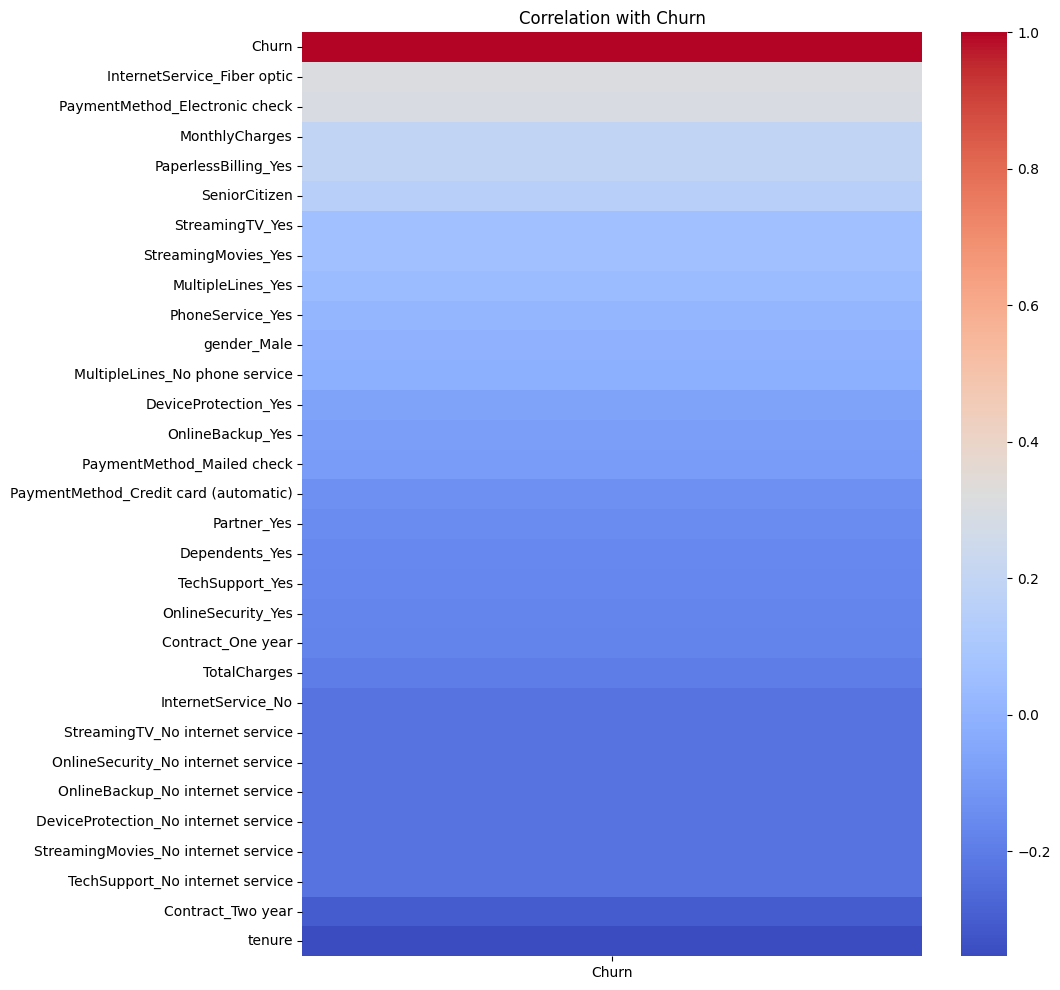

In [12]:
plt.figure(figsize=(10, 12))
correlation = telecom_cust_dummies.corr()[["Churn"]].sort_values(by="Churn", ascending=False)
sns.heatmap(correlation, annot=False, cmap="coolwarm")
plt.title("Correlation with Churn")
plt.show()

### 13. Create a histogram of the “tenure” column

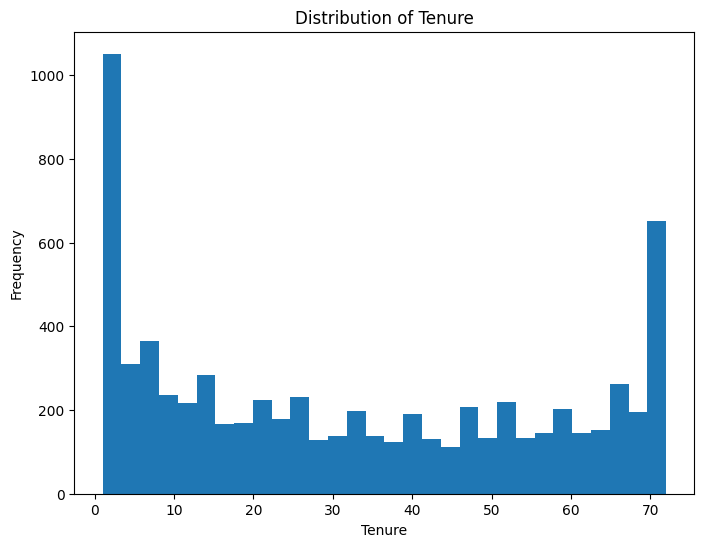

In [13]:
plt.figure(figsize=(8, 6))
plt.hist(telco_df["tenure"], bins=30)
plt.title("Distribution of Tenure")
plt.xlabel("Tenure")
plt.ylabel("Frequency")
plt.show()

### 14. Create a scatter plot of “MonthlyCharges” vs. “TotalCharges

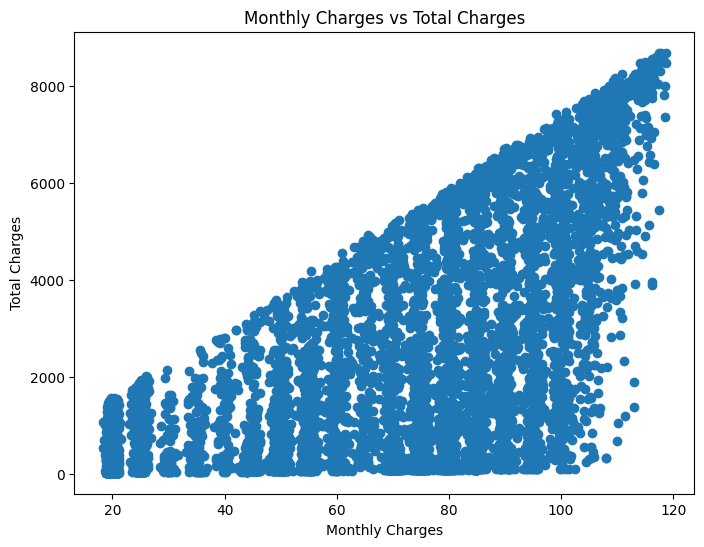

In [14]:
plt.figure(figsize=(8, 6))
plt.scatter(telco_df["MonthlyCharges"], telco_df["TotalCharges"])
plt.xlabel("Monthly Charges")
plt.ylabel("Total Charges")
plt.title("Monthly Charges vs Total Charges")
plt.show()

## Preparation for Machine Learning

### 16. Scale all the variables to a range of 0 to 1 using min-max scaling

In [15]:
# Min-Max scaling
X = telecom_cust_dummies.drop("Churn", axis=1)
y = telecom_cust_dummies["Churn"]

scaler = MinMaxScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X),
    columns=X.columns
)

### 17. Split the dataset into training and test sets (X_train; X_test; y_train; y_test) with a test size of 25%.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

## Logistic Regression

### 18. Import and train a logistic regression model on the training data

In [18]:
telco_model = LogisticRegression(max_iter=1000)
telco_model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

### 19. Make predictions on the test data

In [19]:
y_pred = telco_model.predict(X_test)

### 20. Calculate and print the accuracy score of the logistic regression model

In [21]:
accuracy = accuracy_score(y_test, y_pred)
print("Logistic Regression Accuracy", accuracy)

Logistic Regression Accuracy 0.8060295790671217


## Random Forest Model

### 21. Create a random forest classifi er and tune the following hyperparameters:
a. The number of decision trees in the forest should be 2 000.

In [22]:
telco_rf_model = RandomForestClassifier(n_estimators=2000, oob_score=True, max_features='sqrt', max_leaf_nodes=50, bootstrap=True, random_state=42, n_jobs=-1)

### 22. Fit the model

In [23]:
telco_rf_model.fit(X_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",2000
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",50
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(

### 23. Make predictions on the new test data.

In [24]:
telco_rf_preds = telco_rf_model.predict(X_test)

### 24. Calculate and print the accuracy score of the random forest classifier

In [25]:
telco_rf_accuracy = accuracy_score(y_test, telco_rf_preds)
print("Random Forest Accuracy:", telco_rf_accuracy)

Random Forest Accuracy: 0.7918088737201365


### 25. Calculate and print the OOB error estimation. Explain how well the model generalises to unseen data. You can determine this estimation by subtracting the OOB score of your model, (MODEL_NAME.oob_score_), from 1.

In [26]:
oob_error = 1 - telco_rf_model.oob_score_
print("OOB Error Estimation:", oob_error)

print("Interpretation: Lower OOB error indicates better generalisation to unseen data")

OOB Error Estimation: 0.2007963594994312
Interpretation: Lower OOB error indicates better generalisation to unseen data


## Enhanced model evaluation

### 26. Implement code to calculate the confusion matrix for both the logistic regression and random forest models

In [27]:
telco_cm = confusion_matrix(y_test, telco_rf_preds)
telco_rf_cm = confusion_matrix(y_test, telco_rf_preds)

print("\\nLogistic Regression Confusion Matrix")
print(telco_cm)

print("\\nRandom Forest Confusion Matrix")
print(telco_rf_cm)

\nLogistic Regression Confusion Matrix
[[1174  117]
 [ 249  218]]
\nRandom Forest Confusion Matrix
[[1174  117]
 [ 249  218]]


### 27. Compute the precision and recall scores for each model

In [28]:
telco_precision = precision_score(y_test, y_pred)
telco_recall = recall_score(y_test, y_pred)

rf_precision = precision_score(y_test, telco_rf_preds)
rf_recall = recall_score(y_test, y_pred)

print("\\nLogistic Regression Precision: ", telco_precision)
print("Logistic Regression recall: ", telco_recall)

print("\\nRandom Forest Precision: ", rf_precision)
print("Random Forest Recall: ", rf_recall)



\nLogistic Regression Precision:  0.6544117647058824
Logistic Regression recall:  0.5717344753747323
\nRandom Forest Precision:  0.6507462686567164
Random Forest Recall:  0.5717344753747323


### 28. Discuss what the confusion matrix reveals about the model's performance. Analyse the precision and recall scores to understand the trade-off between correctly and incorrectly identifying churned customers

In [30]:
print(" Confusion Matrix shows the True Positives, True Negatives, False Positives and False Negatives.")
print(" Precision measures how many predicted customers churned the services")
print(" Recall measures how many actual customers who were churned were identifies")

 Confusion Matrix shows the True Positives, True Negatives, False Positives and False Negatives.
 Precision measures how many predicted customers churned the services
 Recall measures how many actual customers who were churned were identifies


### 29. Compare the logistic regression and random forest models based on these additional metrics. Which model is more suitable for this specifi c task, and why?

In [29]:
print("The model which is best at the task is the Logistic Regression model as it has a 0.6544117647058824 accuracy")

The model which is best at the task is the Logistic Regression model as it has a 0.6544117647058824 accuracy
